In [4]:
pip install pandas numpy matplotlib seaborn nltk worldcloud

Note: you may need to restart the kernel to use updated packages.


ERROR: Could not find a version that satisfies the requirement worldcloud (from versions: none)
ERROR: No matching distribution found for worldcloud


In [5]:
# Amazon Reviews Sentiment Analysis Project

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re

# Load Dataset
df = pd.read_csv("Amazon_Reviews.csv")

# Display First 5 Rows
print("First 5 Rows:")
print(df.head())

# Dataset Information
print("\nDataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

# Missing Values
print("\nMissing Values:")
print(df.isnull().sum())

# Duplicate Values
print("\nDuplicate Rows:", df.duplicated().sum())

# Remove Duplicate Rows
df = df.drop_duplicates()

# Remove Rows with Missing Values
df = df.dropna()

# Text Cleaning
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\S+", "", text)
    text = re.sub(r"[^a-zA-Z\s]", "", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

print("\nAvailable Columns:")
print(df.columns.tolist())

First 5 Rows:
      Reviewer Name                     Profile Link Country Review Count  \
0        Eugene ath  /users/66e8185ff1598352d6b3701a      US     1 review   
1  Daniel ohalloran  /users/5d75e460200c1f6a6373648c      GB    9 reviews   
2          p fisher  /users/546cfcf1000064000197b88f      GB   90 reviews   
3         Greg Dunn  /users/62c35cdbacc0ea0012ccaffa      AU    5 reviews   
4     Sheila Hannah  /users/5ddbe429478d88251550610e      GB    8 reviews   

                Review Date                  Rating  \
0  2024-09-16T13:44:26.000Z  Rated 1 out of 5 stars   
1  2024-09-16T18:26:46.000Z  Rated 1 out of 5 stars   
2  2024-09-16T21:47:39.000Z  Rated 1 out of 5 stars   
3  2024-09-17T07:15:49.000Z  Rated 1 out of 5 stars   
4  2024-09-16T18:37:17.000Z  Rated 1 out of 5 stars   

                                      Review Title  \
0       A Store That Doesn't Want to Sell Anything   
1           Had multiple orders one turned up and…   
2                      I infor

In [6]:
# Step 2: Data Cleaning

# Remove duplicate rows
df = df.drop_duplicates()

# Remove rows where review text is missing
df = df.dropna(subset=["Review Text"])

# Convert review text to string
df["Review Text"] = df["Review Text"].astype(str)

# Clean review text
import re

def clean_text(text):
    text = text.lower()
    text = re.sub(r"http\S+|www\S+", "", text)
    text = re.sub(r"[^a-zA-Z\s]", "", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["Cleaned Review"] = df["Review Text"].apply(clean_text)

# Show cleaned data
print("Dataset Shape After Cleaning:", df.shape)

df[["Review Text", "Cleaned Review"]].head()

Dataset Shape After Cleaning: (20946, 10)


,Review Text,Cleaned Review
0,"I registered on the website, tried to order a ...",i registered on the website tried to order a l...
1,Had multiple orders one turned up and driver h...,had multiple orders one turned up and driver h...
2,I informed these reprobates that I WOULD NOT B...,i informed these reprobates that i would not b...
3,I have bought from Amazon before and no proble...,i have bought from amazon before and no proble...
4,If I could give a lower rate I would! I cancel...,if i could give a lower rate i would i cancell...


Dataset Shape: (20946, 10)

Missing Values:
Reviewer Name         0
Profile Link          0
Country               0
Review Count          0
Review Date           0
Rating                0
Review Title          0
Review Text           0
Date of Experience    0
Cleaned Review        0
dtype: int64

Duplicate Rows: 0

Rating Distribution:
Rating
Rated 1 out of 5 stars    13120
Rated 5 out of 5 stars     4447
Rated 4 out of 5 stars     1278
Rated 2 out of 5 stars     1227
Rated 3 out of 5 stars      874
Name: count, dtype: int64


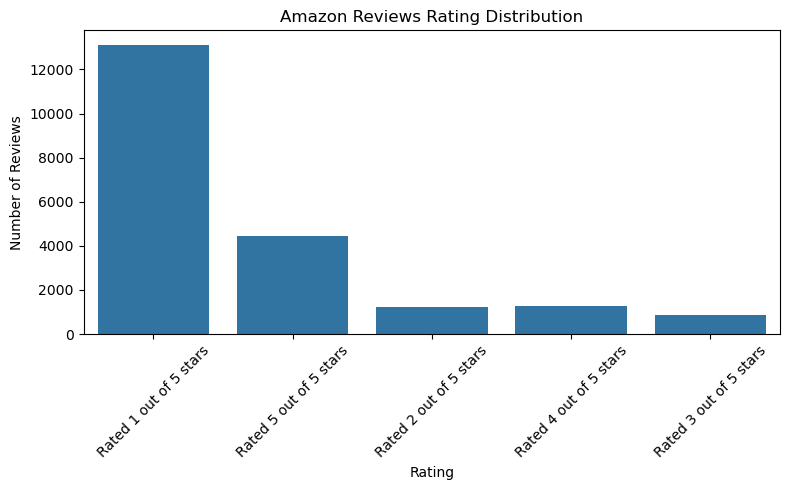

Dataset Shape: (20946, 10)

Missing Values:
Reviewer Name         0
Profile Link          0
Country               0
Review Count          0
Review Date           0
Rating                0
Review Title          0
Review Text           0
Date of Experience    0
Cleaned Review        0
dtype: int64

Duplicate Rows: 0

Rating Distribution:
Rating
Rated 1 out of 5 stars    13120
Rated 5 out of 5 stars     4447
Rated 4 out of 5 stars     1278
Rated 2 out of 5 stars     1227
Rated 3 out of 5 stars      874
Name: count, dtype: int64


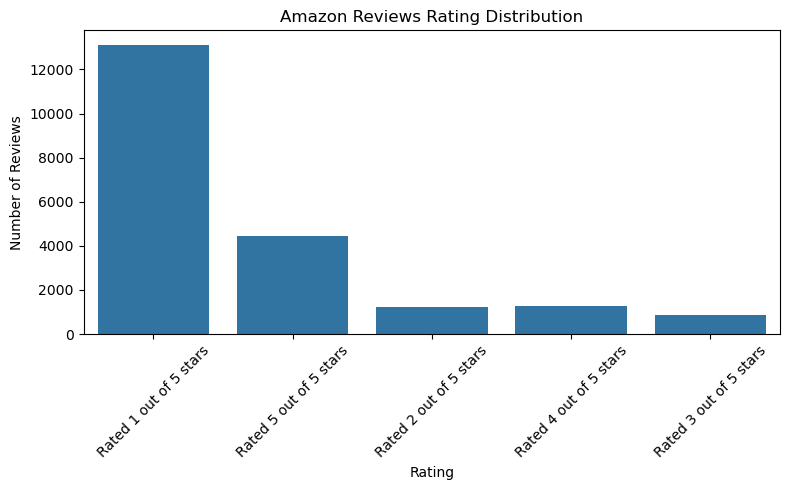

In [7]:
# Step 3: Exploratory Data Analysis (EDA)

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Dataset Information
print("Dataset Shape:", df.shape)

# Check Missing Values
print("\nMissing Values:")
print(df.isnull().sum())

# Check Duplicate Rows
print("\nDuplicate Rows:", df.duplicated().sum())

# Rating Distribution
print("\nRating Distribution:")
print(df["Rating"].value_counts())

# Visualize Rating Distribution
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="Rating")
plt.title("Amazon Reviews Rating Distribution")
plt.xlabel("Rating")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()# Step 3: Exploratory Data Analysis (EDA)

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Dataset Information
print("Dataset Shape:", df.shape)

# Check Missing Values
print("\nMissing Values:")
print(df.isnull().sum())

# Check Duplicate Rows
print("\nDuplicate Rows:", df.duplicated().sum())

# Rating Distribution
print("\nRating Distribution:")
print(df["Rating"].value_counts())

# Visualize Rating Distribution
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="Rating")
plt.title("Amazon Reviews Rating Distribution")
plt.xlabel("Rating")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Rating Distribution:
Rating
Rated 1 out of 5 stars    13120
Rated 5 out of 5 stars     4447
Rated 4 out of 5 stars     1278
Rated 2 out of 5 stars     1227
Rated 3 out of 5 stars      874
Name: count, dtype: int64

Sentiment Distribution:
Sentiment
Negative    14347
Positive     5725
Neutral       874
Name: count, dtype: int64


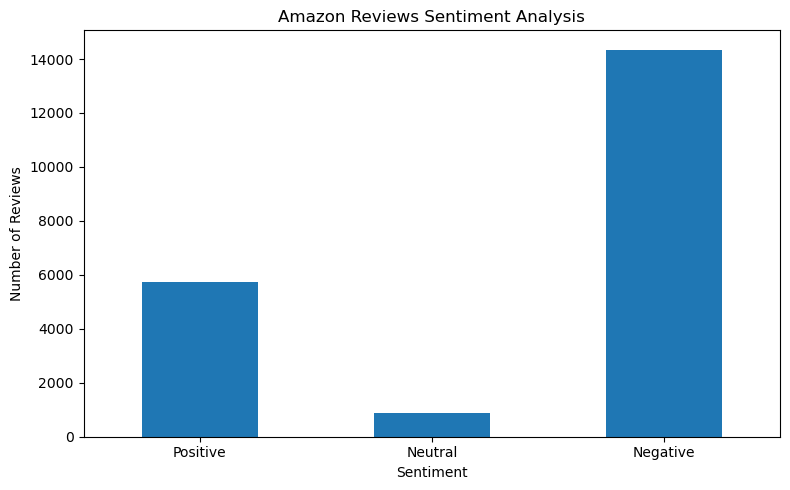

In [8]:
# Step 4: Sentiment Analysis

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Check rating distribution
print("Rating Distribution:")
print(df["Rating"].value_counts())

# Convert rating text into numeric values
df["Rating_Number"] = (
    df["Rating"]
    .astype(str)
    .str.extract(r"(\d+)")
    .astype(float)
)

# Classify sentiment based on rating
def get_sentiment(rating):
    if pd.isna(rating):
        return "Unknown"
    elif rating >= 4:
        return "Positive"
    elif rating == 3:
        return "Neutral"
    else:
        return "Negative"

df["Sentiment"] = df["Rating_Number"].apply(get_sentiment)

# Display sentiment counts
print("\nSentiment Distribution:")
print(df["Sentiment"].value_counts())

# Plot sentiment distribution
df["Sentiment"].value_counts().reindex(
    ["Positive", "Neutral", "Negative"]
).plot(kind="bar", figsize=(8, 5))

plt.title("Amazon Reviews Sentiment Analysis")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Sentiment Counts:
Sentiment
Negative    14347
Positive     5725
Neutral       874
Name: count, dtype: int64

Sentiment Percentage:
Sentiment
Negative    68.50
Positive    27.33
Neutral      4.17
Name: count, dtype: float64


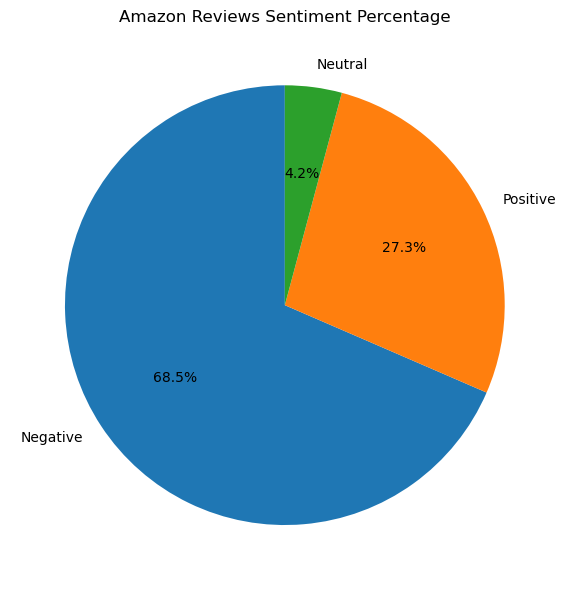

In [9]:
# Step 5: Sentiment Percentage Analysis

import matplotlib.pyplot as plt

# Count sentiments
sentiment_counts = df["Sentiment"].value_counts()

# Calculate percentages
sentiment_percentage = (
    sentiment_counts / sentiment_counts.sum()
) * 100

print("Sentiment Counts:")
print(sentiment_counts)

print("\nSentiment Percentage:")
print(sentiment_percentage.round(2))

# Create Pie Chart
plt.figure(figsize=(8, 6))

plt.pie(
    sentiment_counts,
    labels=sentiment_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Amazon Reviews Sentiment Percentage")
plt.tight_layout()
plt.show()

# Amazon Reviews Sentiment Analysis

## Project Overview
The Amazon Reviews Sentiment Analysis project analyzes customer reviews to understand customer opinions and sentiment patterns using Python.

## Objectives
- Analyze customer reviews.
- Explore review data and identify patterns.
- Perform Exploratory Data Analysis (EDA).
- Visualize insights from customer reviews.

## Tools Used
- Python
- Pandas
- Matplotlib
- Seaborn
- Jupyter Notebook

## Key Findings
- Negative reviews form the largest category.
- Positive reviews represent a smaller portion of the dataset.
- Neutral reviews account for the smallest category.

## Conclusion
The analysis shows that negative reviews form the largest category in this dataset. This indicates that many customers expressed dissatisfaction in their reviews.

## Future Scope
- Apply Natural Language Processing (NLP).
- Use machine learning to classify review text.
- Explore common topics in negative reviews.